# ⚡ VOLTA — Track B: GRU and LSTM feature experiments

Forecast `price actual` for the next 24 hours (one forecast per day at 00:00 UTC) from the previous 168 hours.
**E0** = price only; every other experiment adds **one** group to the price. Both models use the same data, windows and settings.
Metric: **MAE (EUR/MWh)**, lower is better. Train 2015–2016, validation 2017; the 2018 test set is not used here.

| Exp | Inputs |
|---|---|
| E0 | price only |
| E1 | price + `is_weekend` |
| E2 | price + load and generation |
| E3 | price + `sin_hour`, `cos_hour` |
| E4 | price + `sin_dow`, `cos_dow` |
| E5 | price + `is_holiday` |
| E6 | price + weather (5 cities) |

## 1. Data preparation

### 1.1 Load the clean data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
import holidays                                   # pip install holidays (Spanish public holidays)

CANDIDATES = ["../data/processed/volta_clean_hourly.csv",
              "data/processed/volta_clean_hourly.csv",
              "volta_clean_hourly.csv"]
TARGET = "price actual"

def utc(s):
    return pd.Timestamp(s, tz="UTC")

DATA_PATH = next((p for p in CANDIDATES if Path(p).exists()), None)
assert DATA_PATH, "volta_clean_hourly.csv not found: add its path to CANDIDATES"

df = pd.read_csv(DATA_PATH)
df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.sort_values("time").set_index("time")
assert df.index.equals(pd.date_range(df.index.min(), df.index.max(), freq="h", tz="UTC"))   # complete hourly grid
print("rows:", len(df), "|", df.index.min(), "->", df.index.max())

2026-10-13 11:52:05.298853: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-13 11:52:05.304527: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-13 11:52:05.325979: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-13 11:52:05.359609: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-13 11:52:05.392562: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registe

rows: 35064 | 2014-12-31 23:00:00+00:00 -> 2018-12-31 22:00:00+00:00


### 1.2 Feature groups

In [2]:
CITIES = ["barcelona", "bilbao", "madrid", "seville", "valencia"]
WEATHER_TYPES = ["temp", "humidity", "clouds_all", "rain_1h"]

# energy: price, load and non-constant generation (no forecast columns)
const_cols = [c for c in df.columns if df[c].nunique() <= 1]
GEN = [c for c in df.columns if c.startswith("generation") and c not in const_cols]
ENERGY = [TARGET, "total load actual"] + GEN

# calendar from Spanish local time (known in advance)
local = df.index.tz_convert("Europe/Madrid")
es_holidays = holidays.Spain(years=range(local.year.min(), local.year.max() + 1))
hour, dow = np.asarray(local.hour), np.asarray(local.dayofweek)
cal = pd.DataFrame(index=df.index)
cal["is_weekend"] = (dow >= 5).astype(float)
cal["sin_hour"], cal["cos_hour"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
cal["sin_dow"],  cal["cos_dow"]  = np.sin(2 * np.pi * dow / 7),   np.cos(2 * np.pi * dow / 7)
cal["is_holiday"] = [float(d in es_holidays) for d in local.date]
CAL_COLS = list(cal.columns)

# weather: observed values, used from the past only
WEATHER = [f"{c}_{w}" for c in CITIES for w in WEATHER_TYPES]

print("energy:", len(ENERGY), "| calendar:", len(CAL_COLS), "| weather:", len(WEATHER))

energy: 16 | calendar: 6 | weather: 20


### 1.3 Experiments

In [3]:
EXPERIMENTS = {
    "E0": [TARGET],                                              # price only
    "E1": [TARGET, "is_weekend"],                                # + weekend flag
    "E2": [TARGET] + [c for c in ENERGY if c != TARGET],         # + load and generation
    "E3": [TARGET, "sin_hour", "cos_hour"],                      # + daily cycle
    "E4": [TARGET, "sin_dow", "cos_dow"],                        # + weekly cycle
    "E5": [TARGET, "is_holiday"],                                # + public holidays
    "E6": [TARGET] + WEATHER,                                    # + weather
}
ALL_COLS = ENERGY + CAL_COLS + WEATHER                           # every column any experiment can use

### 1.4 Split by date and scale (fit on training only)

In [4]:
TRAIN_START, TRAIN_END = "2015-01-01", "2016-12-31"
VAL_START,   VAL_END   = "2017-01-01", "2017-12-31"

train_mask = (df.index >= utc(TRAIN_START)) & (df.index <= utc(TRAIN_END) + pd.Timedelta(hours=23))

CONT = ENERGY + WEATHER
scaler = MinMaxScaler().fit(df.loc[train_mask, CONT])                         # fit on train only
target_scaler = MinMaxScaler().fit(df.loc[train_mask, [TARGET]])              # to convert back to EUR/MWh

feat = pd.concat([pd.DataFrame(scaler.transform(df[CONT]), index=df.index, columns=CONT), cal], axis=1)
F_ARR   = feat[ALL_COLS].to_numpy(dtype="float32")                           # past-window inputs
CAL_ARR = cal[CAL_COLS].to_numpy(dtype="float32")                            # calendar of the forecast hours
y_all   = target_scaler.transform(df[[TARGET]]).ravel()

### 1.5 Windows: 168 past hours → next 24 hours

In [5]:
INPUT_WINDOW = 168        # hours of history
H = 24                    # forecast horizon (hours)

train_days = pd.date_range(utc(TRAIN_START) + pd.Timedelta(hours=INPUT_WINDOW), utc(TRAIN_END), freq="D")
val_days   = pd.date_range(utc(VAL_START), utc(VAL_END), freq="D")          # one forecast per day at 00:00 UTC
idx = df.index

def make_windows(days):
    pos = idx.get_indexer(days)
    X_win = np.stack([F_ARR[p - INPUT_WINDOW: p] for p in pos])               # past 168 h (all columns)
    X_cal = np.stack([CAL_ARR[p: p + H] for p in pos])                        # calendar of the 24 forecast hours
    y     = np.stack([y_all[p: p + H] for p in pos])                          # 24 target prices
    return X_win, X_cal, y

Xw_train, Xc_train, y_train = make_windows(train_days)
Xw_val,   Xc_val,   y_val   = make_windows(val_days)
y_val_eur = target_scaler.inverse_transform(y_val.reshape(-1, 1)).reshape(y_val.shape)   # actual prices
print("train:", Xw_train.shape, "| val:", Xw_val.shape)

train: (724, 168, 42) | val: (365, 168, 42)


### 1.6 Model and training functions (shared by both sections)

Window → GRU or LSTM layer → (+ calendar of the forecast hours) → Dense(24).

In [6]:
UNITS      = 32
BATCH      = 32
MAX_EPOCHS = 1000        # upper limit; early stopping decides
PATIENCE   = 10
SEED       = 42

def build_model(layer, n_feat, n_cal):
    win_in = keras.Input(shape=(INPUT_WINDOW, n_feat))
    h = layer(UNITS)(win_in)
    if n_cal == 0:                                                           # no calendar column
        model = keras.Model(win_in, keras.layers.Dense(H)(h))
    else:
        cal_in = keras.Input(shape=(H, n_cal))
        h = keras.layers.Concatenate()([h, keras.layers.Flatten()(cal_in)])
        model = keras.Model([win_in, cal_in], keras.layers.Dense(H)(h))
    model.compile(optimizer="adam", loss="mae")
    return model

def run_experiments(layer):
    """Train one model per experiment; return MAE table, histories and predictions (EUR/MWh)."""
    rows, hists, preds = [], {}, {}
    for name, cols in EXPERIMENTS.items():
        ix = [ALL_COLS.index(c) for c in cols]
        cx = [CAL_COLS.index(c) for c in cols if c in CAL_COLS]
        tr = [Xw_train[:, :, ix], Xc_train[:, :, cx]] if cx else Xw_train[:, :, ix]
        va = [Xw_val[:, :, ix],   Xc_val[:, :, cx]]   if cx else Xw_val[:, :, ix]

        keras.utils.set_random_seed(SEED)
        model = build_model(layer, len(ix), len(cx))
        early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        hist = model.fit(tr, y_train, validation_data=(va, y_val), epochs=MAX_EPOCHS,
                         batch_size=BATCH, shuffle=False, callbacks=[early], verbose=0)

        p = model.predict(va, verbose=0)
        preds[name] = target_scaler.inverse_transform(p.reshape(-1, 1)).reshape(p.shape)
        hists[name] = hist.history
        rows.append({"exp": name, "MAE": np.abs(y_val_eur - preds[name]).mean(), "epochs": len(hist.history["loss"])})
        print(f"{name}: MAE {rows[-1]['MAE']:.2f} | epochs {rows[-1]['epochs']}")

    table = pd.DataFrame(rows).set_index("exp")
    table["vs E0"] = table["MAE"] - table.loc["E0", "MAE"]                     # negative = the group helped
    return table.round(2), hists, preds

def plot_results(table, hists, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].bar(table.index, table["MAE"], color="#1b9e77")
    axes[0].axhline(table.loc["E0", "MAE"], color="black", ls="--", lw=0.8, label="E0 (price only)")
    axes[0].set_ylabel("MAE (EUR/MWh)"); axes[0].set_title(f"{title}: validation MAE"); axes[0].legend()
    for name, h in hists.items():
        axes[1].plot(h["val_loss"], label=name)
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation MAE (scaled)")
    axes[1].set_title(f"{title}: validation loss"); axes[1].legend(fontsize=8, ncol=2)
    plt.tight_layout(); plt.show()

## 2. GRU

In [7]:
gru_table, gru_hists, gru_preds = run_experiments(keras.layers.GRU)

E0: MAE 4.31 | epochs 302
E1: MAE 3.93 | epochs 234
E2: MAE 4.85 | epochs 99
E3: MAE 4.81 | epochs 99
E4: MAE 4.25 | epochs 101
E5: MAE 4.42 | epochs 205
E6: MAE 5.35 | epochs 65


In [8]:
gru_table

,MAE,epochs,vs E0
exp,,,
E0,4.31,302,0.00
E1,3.93,234,-0.39
E2,4.85,99,0.53
E3,4.81,99,0.49
E4,4.25,101,-0.06
E5,4.42,205,0.11
E6,5.35,65,1.03


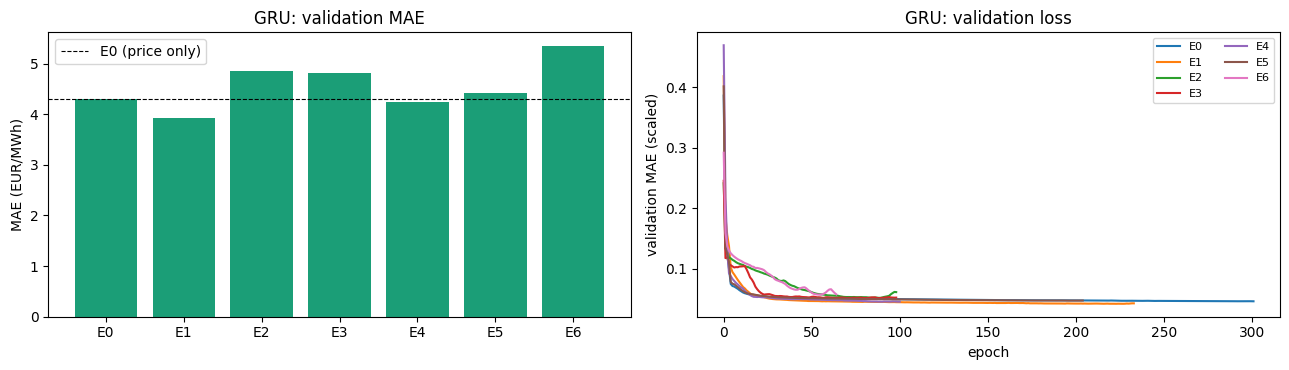

In [9]:
plot_results(gru_table, gru_hists, "GRU")

## 3. LSTM

In [10]:
lstm_table, lstm_hists, lstm_preds = run_experiments(keras.layers.LSTM)

E0: MAE 4.46 | epochs 107
E1: MAE 4.05 | epochs 148
E2: MAE 4.88 | epochs 90
E3: MAE 4.88 | epochs 112
E4: MAE 4.21 | epochs 162
E5: MAE 4.69 | epochs 84
E6: MAE 9.63 | epochs 23


In [11]:
lstm_table

,MAE,epochs,vs E0
exp,,,
E0,4.46,107,0.00
E1,4.05,148,-0.41
E2,4.88,90,0.43
E3,4.88,112,0.42
E4,4.21,162,-0.24
E5,4.69,84,0.24
E6,9.63,23,5.18


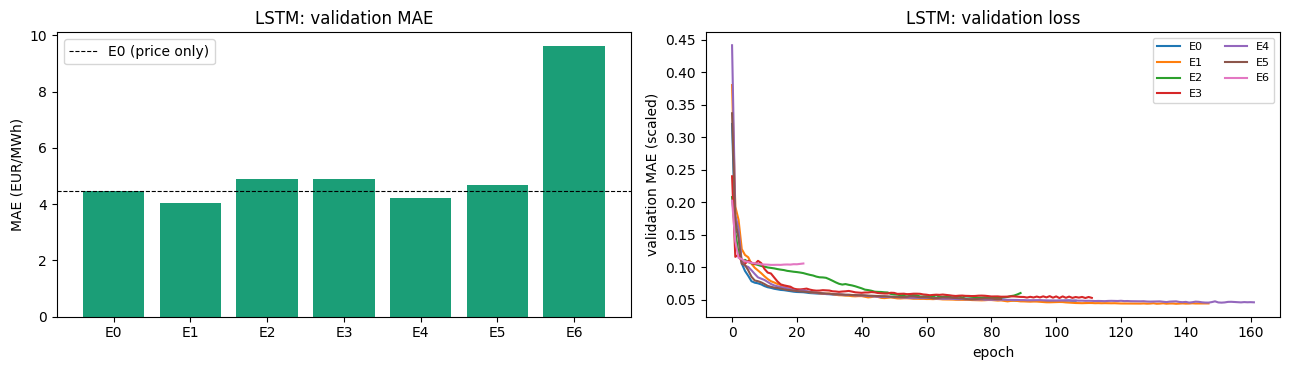

In [12]:
plot_results(lstm_table, lstm_hists, "LSTM")

## 4. GRU vs LSTM

In [13]:
# MAE per experiment, both models side by side
compare = pd.DataFrame({"GRU": gru_table["MAE"], "LSTM": lstm_table["MAE"]})
compare["best"] = compare.idxmin(axis=1)
compare

,GRU,LSTM,best
exp,,,
E0,4.31,4.46,GRU
E1,3.93,4.05,GRU
E2,4.85,4.88,GRU
E3,4.81,4.88,GRU
E4,4.25,4.21,LSTM
E5,4.42,4.69,GRU
E6,5.35,9.63,GRU


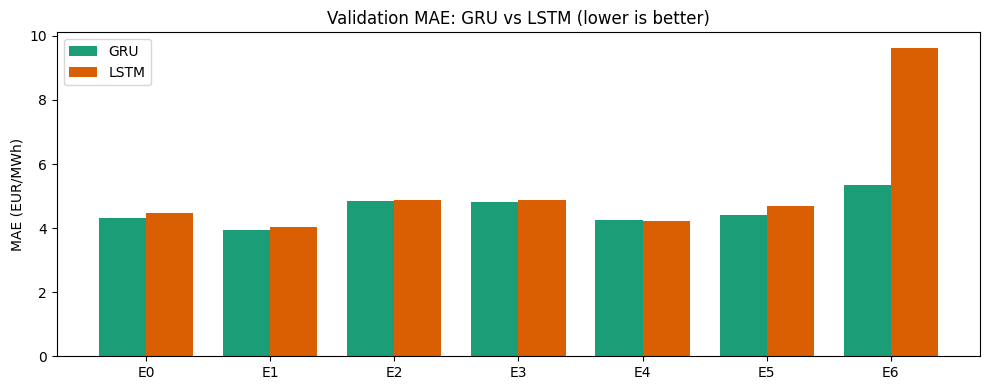

In [14]:
x, w = np.arange(len(compare)), 0.38
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w / 2, compare["GRU"],  w, label="GRU",  color="#1b9e77")
ax.bar(x + w / 2, compare["LSTM"], w, label="LSTM", color="#d95f02")
ax.set_xticks(x); ax.set_xticklabels(compare.index)
ax.set_ylabel("MAE (EUR/MWh)"); ax.set_title("Validation MAE: GRU vs LSTM (lower is better)"); ax.legend()
plt.tight_layout(); plt.show()

### 4.1 Best model vs the team baselines

Same baselines as the team baseline notebook: the last 24 h / 168 h of training, repeated over 2017.

In [15]:
price = df[TARGET]
val_hours = pd.date_range(utc(VAL_START), periods=len(val_days) * H, freq="h", tz="UTC")
actual = price.reindex(val_hours).values
train_end = utc(TRAIN_END) + pd.Timedelta(hours=23)

results = {}
for L in (24, 168):                                                            # seasonal naive from training only
    season = price.loc[train_end - pd.Timedelta(hours=L - 1): train_end].values
    results[f"seasonal_{L}"] = np.abs(actual - season[np.arange(len(actual)) % L]).mean()

exp, model_name = compare[["GRU", "LSTM"]].stack().idxmin()                    # lowest MAE overall
best_pred = (gru_preds if model_name == "GRU" else lstm_preds)[exp].ravel()
results[f"{model_name} {exp}"] = np.abs(actual - best_pred).mean()

summary = pd.DataFrame({"MAE": results}).round(2)
summary["improvement vs seasonal_24 (%)"] = ((1 - summary["MAE"] / summary.loc["seasonal_24", "MAE"]) * 100).round(1)
print(f"Best: {model_name} {exp} -> inputs {EXPERIMENTS[exp]}")
summary

Best: GRU E1 -> inputs ['price actual', 'is_weekend']


,MAE,improvement vs seasonal_24 (%)
seasonal_24,11.41,0.0
seasonal_168,10.98,3.8
GRU E1,3.93,65.6


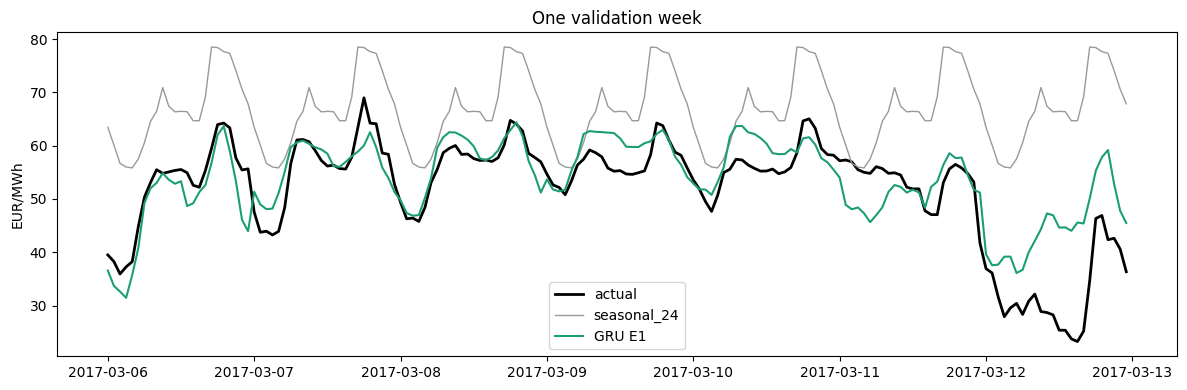

In [16]:
# one validation week: actual vs best model vs seasonal_24
week = (val_hours >= utc("2017-03-06")) & (val_hours < utc("2017-03-13"))
season24 = price.loc[train_end - pd.Timedelta(hours=23): train_end].values[np.arange(len(actual)) % 24]
plt.figure(figsize=(12, 4))
plt.plot(val_hours[week], actual[week], color="black", lw=2, label="actual")
plt.plot(val_hours[week], season24[week], color="#999999", lw=1, label="seasonal_24")
plt.plot(val_hours[week], best_pred[week], color="#1b9e77", lw=1.5, label=f"{model_name} {exp}")
plt.ylabel("EUR/MWh"); plt.title("One validation week"); plt.legend()
plt.tight_layout(); plt.show()